# Seminar 6 - Modele de clasificare: Arbori de decizie vs. Regresie logistică

**Obiective:**
După finalizarea acestui laborator, veți putea:
- să utilizați scikit-learn pentru a implementa modele de clasificare (arbori de decizie și regresie logistică);
- să creați un model, să îl antrenați, să îl testați și să îl utilizați pentru predicție;
- să evaluați și să comparați modelele folosind acuratețea, precizia, recall, F1, AUC, log loss, matricea de confuzie și curba ROC;
- să interpretați un arbore de clasificare și coeficienții unei regresii logistice.

In [ ]:
!pip install scikit-learn

In [ ]:
# Biblioteci de bază
import pandas as pd
import numpy as np

In [ ]:
# Biblioteci de Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import tree

In [ ]:
# Biblioteci pentru metrici
from sklearn import metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, log_loss,
                             confusion_matrix, classification_report)

In [ ]:
# Biblioteci de vizualizare
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set()

# Alte setări
import warnings
warnings.filterwarnings('ignore')

# **Predicția nivelului de venit al unei persoane (Adult Census Income)**

Se va folosi setul de date **Adult** (cunoscut și ca *Census Income*), extras din recensământul SUA din 1994. Baza de date conține **48.842 de persoane** și **14 variabile** explicative, numerice și categoriale, referitoare la caracteristici demografice și profesionale: vârstă, nivel de educație, ocupație, stare civilă, număr de ore lucrate pe săptămână, câștiguri de capital etc.

Variabila target este variabila **income**, care arată dacă venitul anual al unei persoane depășește **50.000 $** (`>50K`) sau nu (`<=50K`). Putem folosi aceste date pentru a previziona dacă o persoană are un venit ridicat sau nu în funcție de variabilele disponibile. Astfel de modele sunt utile, de exemplu, în marketing (segmentarea clienților), în evaluarea eligibilității pentru credite sau în analiza politicilor publice.

Baza de date este preluată din UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/2/adult

| Variabilă | Descriere | Tip |
|---|---|---|
| age | vârsta | numerică |
| workclass | tipul angajatorului (privat, de stat, independent etc.) | categorială |
| fnlwgt | pondere statistică a recensământului | numerică |
| education | nivelul de educație | categorială |
| education-num | nivelul de educație, codificat numeric (1-16) | numerică |
| marital-status | starea civilă | categorială |
| occupation | ocupația | categorială |
| relationship | relația în cadrul gospodăriei | categorială |
| race | rasa | categorială |
| sex | sexul | categorială |
| capital-gain | câștiguri de capital | numerică |
| capital-loss | pierderi de capital | numerică |
| hours-per-week | ore lucrate pe săptămână | numerică |
| native-country | țara de origine | categorială |
| **income** | **venit >50K sau <=50K (target)** | **binară** |

In [ ]:
# Citirea datelor într-un dataframe
# Fișierul nu are antet, așa că dăm noi numele coloanelor.
# Valorile lipsă sunt codificate în fișier cu '?'.

coloane = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
           'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
           'hours-per-week', 'native-country', 'income']

url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv'
adult_df = pd.read_csv(url, header=None, names=coloane, na_values='?', skipinitialspace=True)

# Alternativ, dacă ați descărcat fișierul local:
# adult_df = pd.read_csv('adult-all.csv', header=None, names=coloane, na_values='?', skipinitialspace=True)

In [ ]:
# Afișarea primelor 10 linii din tabel
adult_df.head(10)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
5,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
6,49,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K
7,52,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,>50K
8,31,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50,United-States,>50K
9,42,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40,United-States,>50K


In [ ]:
adult_df.shape

(48842, 15)

In [ ]:
# Tipurile variabilelor
adult_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       46043 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      46033 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  47985 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [ ]:
# Statistici descriptive pentru variabilele numerice
adult_df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


**Distribuția variabilei target**

Înainte de modelare este important să vedem cât de echilibrate sunt clasele. Dacă o clasă este mult mai frecventă, acuratețea singură poate fi înșelătoare.

income
<=50K    37155
>50K     11687
Name: count, dtype: int64

income
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64


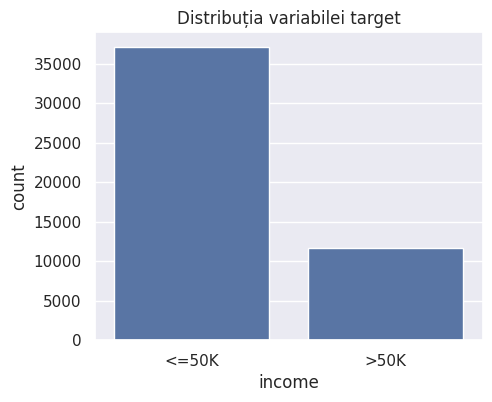

In [ ]:
print(adult_df['income'].value_counts())
print()
print(adult_df['income'].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
sns.countplot(x='income', data=adult_df)
plt.title('Distribuția variabilei target')
plt.show()

**Interpretare:** aproximativ 76% dintre persoane au venit `<=50K` și doar 24% au venit `>50K`. Clasele sunt **dezechilibrate**: un model „naiv” care ar prezice mereu `<=50K` ar avea deja o acuratețe de ~76%. De aceea vom urmări și precizia, recall-ul, F1 și AUC, nu doar acuratețea.

**Câteva relații între variabile și target**

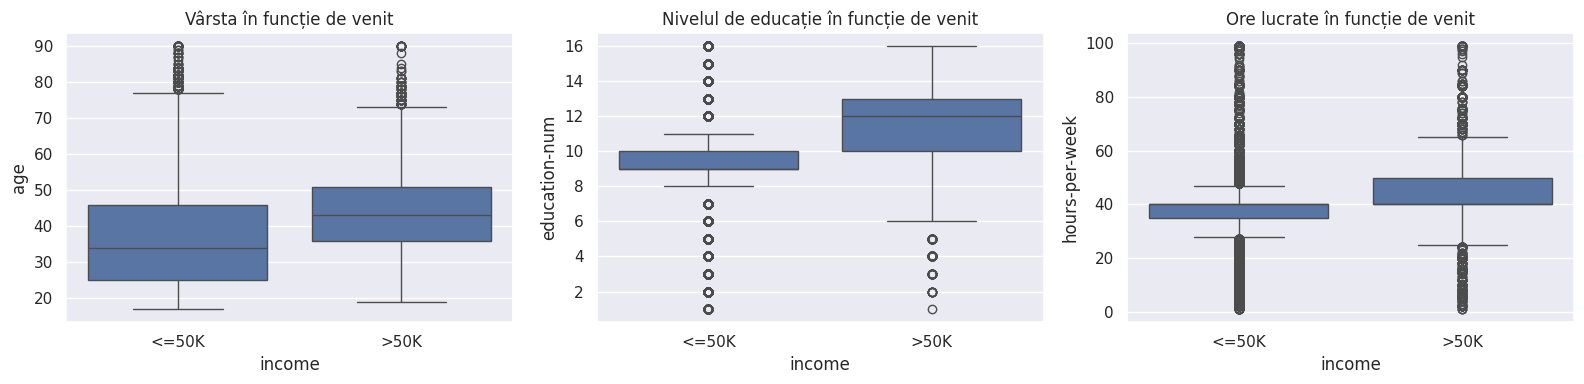

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(x='income', y='age', data=adult_df, ax=axes[0])
axes[0].set_title('Vârsta în funcție de venit')

sns.boxplot(x='income', y='education-num', data=adult_df, ax=axes[1])
axes[1].set_title('Nivelul de educație în funcție de venit')

sns.boxplot(x='income', y='hours-per-week', data=adult_df, ax=axes[2])
axes[2].set_title('Ore lucrate în funcție de venit')

plt.tight_layout()
plt.show()

In [ ]:
# Proporția persoanelor cu venit >50K în funcție de starea civilă
(adult_df.assign(venit_mare = adult_df['income'] == '>50K')
          .groupby('marital-status')['venit_mare'].mean()
          .sort_values(ascending=False).round(3))

,venit_mare
marital-status,
Married-civ-spouse,0.446
Married-AF-spouse,0.378
Divorced,0.101
Married-spouse-absent,0.092
Widowed,0.084
Separated,0.065
Never-married,0.045


# Preprocesarea datelor:
1. Identificarea și eliminarea valorilor lipsă (sunt puține, aproximativ 7% din observații)
2. Eliminarea variabilelor redundante sau fără semnificație economică (`fnlwgt` și `education`)
3. Gruparea categoriilor rare (variabila `native-country`)
4. Transformarea variabilei target în variabilă binară (0/1)
5. Transformarea caracteristicilor categoriale în variabile binare (One-hot encoding)

In [ ]:
# Calculul numărului de valori lipsă din fiecare coloană a dataframe-ului
for col in adult_df.columns:
    if adult_df[col].isnull().sum() > 0:
        print(col, ' - ', adult_df[col].isnull().sum())

workclass  -  2799
occupation  -  2809
native-country  -  857


In [ ]:
# Eliminarea observațiilor cu valori lipsă
adult_df.dropna(inplace=True)

# Verificarea existenței valorilor lipsă în tabel
adult_df.isna().sum().sum()

np.int64(0)

In [ ]:
adult_df.shape

(45222, 15)

**Eliminarea variabilelor redundante**
- `fnlwgt` este o pondere statistică folosită la recensământ, nu o caracteristică a persoanei;
- `education` conține aceeași informație ca `education-num` (educația codificată numeric), deci o păstrăm doar pe cea numerică.

In [ ]:
# Verificăm că education și education-num conțin aceeași informație
adult_df.groupby('education')['education-num'].unique().sort_values()

,education-num
education,
Preschool,[1]
1st-4th,[2]
5th-6th,[3]
7th-8th,[4]
9th,[5]
10th,[6]
11th,[7]
12th,[8]
HS-grad,[9]


In [ ]:
adult_df.drop(['fnlwgt', 'education'], axis=1, inplace=True)
adult_df.shape

(45222, 13)

**Gruparea categoriilor rare**

Variabila `native-country` are peste 40 de categorii, dar marea majoritate a persoanelor provin din SUA. Pentru a nu crea zeci de variabile binare aproape goale, o transformăm într-o variabilă cu două categorii: `United-States` și `Other`.

In [ ]:
print(adult_df['native-country'].value_counts(normalize=True).head(5).round(3))

adult_df['native-country'] = np.where(adult_df['native-country'] == 'United-States', 'United-States', 'Other')
adult_df['native-country'].value_counts()

native-country
United-States    0.913
Mexico           0.020
Philippines      0.006
Germany          0.004
Puerto-Rico      0.004
Name: proportion, dtype: float64


,count
native-country,
United-States,41292
Other,3930


In [ ]:
# Transformarea variabilei target în 0/1:  1 = venit >50K,  0 = venit <=50K
adult_df['income'] = (adult_df['income'] == '>50K').astype(int)
adult_df['income'].value_counts()

,count
income,
0,34014
1,11208


In [ ]:
# Transformarea variabilelor nominale în variabile binare folosind One-hot encoding
# drop_first=True elimină o categorie de referință pentru fiecare variabilă (evită multicoliniaritatea perfectă
# în regresia logistică)

cate_data = adult_df.select_dtypes('object').columns
print(list(cate_data))

adult_df = pd.get_dummies(adult_df, columns=cate_data, drop_first=True, dtype=int)
adult_df.head(3)

['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


,age,education-num,capital-gain,capital-loss,hours-per-week,income,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,native-country_United-States
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,1
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,1,1
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,1,1


In [ ]:
adult_df.shape

(45222, 42)

# Crearea seturilor de date de antrenare și de testare

In [ ]:
# Crearea matricilor pentru sklearn:
X = adult_df.drop('income', axis=1)
y = adult_df['income']

In [ ]:
# Împărțirea setului de date în două: date de training (70%) și date de test (30%).
# stratify=y păstrează aceeași proporție a claselor în ambele seturi (important când clasele sunt dezechilibrate)
random_seed = 50

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=random_seed, stratify=y)

print('Train:', X_train.shape, '  Test:', X_test.shape)
print('Proporția clasei 1 în train:', round(y_train.mean(), 3), '  în test:', round(y_test.mean(), 3))

Train: (31655, 41)   Test: (13567, 41)
Proporția clasei 1 în train: 0.248   în test: 0.248


# Arbori de clasificare

**DecisionTreeClassifier**
(class_weight=None, **criterion='gini'**, **max_depth=3**,

max_features=None, max_leaf_nodes=None,

min_impurity_decrease=0.0,

min_samples_leaf=1, min_samples_split=2,

min_weight_fraction_leaf=0.0, random_state=None,

splitter='best')

Parametri importanți:
- `criterion` – criteriul de selecție a atributelor la fiecare nod: `'gini'` (indicele Gini) sau `'entropy'` (câștigul informațional);
- `max_depth` – adâncimea maximă a arborelui; un arbore prea adânc „învață pe de rost” datele de antrenare (overfitting);
- `min_samples_leaf` – numărul minim de observații dintr-o frunză.

Arborii de decizie **nu necesită standardizarea** variabilelor, deoarece fiecare împărțire se face pe baza unui prag pentru o singură variabilă.

**Creați un arbore de clasificare folosind GINI ca și criteriu de selecție a atributelor**

In [ ]:
# Mai întâi vom crea o instanță a DecisionTreeClassifier numită clf_gini.
# În interiorul clasificatorului, specificați criterion="gini"
clf_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=random_seed)

In [ ]:
# Vom potrivi datele cu matricea caracteristicilor de antrenament X_train și vectorul de răspuns y_train
clf_gini = clf_gini.fit(X_train, y_train)

In [ ]:
# Vom realiza predicții asupra setului de date de testare și le vom stoca într-o variabilă numită y_pred_gini.
y_pred_gini = clf_gini.predict(X_test)
y_pred_gini

array([0, 0, 1, ..., 0, 0, 0], shape=(13567,))

In [ ]:
y_test.head(10)

,income
14110,0
30992,0
34906,0
8389,0
30571,1
10867,0
45161,1
36638,0
21069,0
24159,0


**Observație:** AUC se calculează corect pe baza **probabilităților** prezise (`predict_proba`), nu pe baza claselor prezise (0/1). Dacă folosim clasele, curba ROC are un singur punct, iar AUC-ul este subestimat.

In [ ]:
# Evaluarea modelului
y_prob_gini = clf_gini.predict_proba(X_test)[:, 1]

print("Accuracy_GINI: ", accuracy_score(y_test, y_pred_gini))
print("Precision_GINI:", precision_score(y_test, y_pred_gini))
print("Recall_GINI:   ", recall_score(y_test, y_pred_gini))
print("F1_GINI:       ", f1_score(y_test, y_pred_gini))
print("AUC_GINI:      ", roc_auc_score(y_test, y_prob_gini))

Accuracy_GINI:  0.83968452863566
Precision_GINI: 0.74413821472645
Recall_GINI:    0.5380725758477097
F1_GINI:        0.6245468669083376
AUC_GINI:       0.8612165654644919


**Creați un arbore de clasificare folosind ENTROPY ca și criteriu de selecție a atributelor**

In [ ]:
# Crearea arborelui
...

# Clasificatorul
...

# Predicția
...

# Evaluarea modelului
...

Ellipsis

In [ ]:
# Crearea arborelui - ENTROPY
clf_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=random_seed)

# Clasificatorul
clf_entropy = clf_entropy.fit(X_train, y_train)

# Predicția
y_pred_entropy = clf_entropy.predict(X_test)
y_prob_entropy = clf_entropy.predict_proba(X_test)[:, 1]

In [ ]:
# Evaluarea modelului
print("Accuracy_ENTROPY: ", accuracy_score(y_test, y_pred_entropy))
print("Precision_ENTROPY:", precision_score(y_test, y_pred_entropy))
print("Recall_ENTROPY:   ", recall_score(y_test, y_pred_entropy))
print("F1_ENTROPY:       ", f1_score(y_test, y_pred_entropy))
print("AUC_ENTROPY:      ", roc_auc_score(y_test, y_prob_entropy))

Accuracy_ENTROPY:  0.83968452863566
Precision_ENTROPY: 0.74413821472645
Recall_ENTROPY:    0.5380725758477097
F1_ENTROPY:        0.6245468669083376
AUC_ENTROPY:       0.8612010448506392


**Compararea modelelor**

In [ ]:
comparatie_arbori = pd.DataFrame({
    'GINI':    [accuracy_score(y_test, y_pred_gini), precision_score(y_test, y_pred_gini),
                recall_score(y_test, y_pred_gini), f1_score(y_test, y_pred_gini), roc_auc_score(y_test, y_prob_gini)],
    'ENTROPY': [accuracy_score(y_test, y_pred_entropy), precision_score(y_test, y_pred_entropy),
                recall_score(y_test, y_pred_entropy), f1_score(y_test, y_pred_entropy), roc_auc_score(y_test, y_prob_entropy)]
}, index=['Accuracy', 'Precision', 'Recall', 'F1', 'AUC'])

comparatie_arbori.round(4)

,GINI,ENTROPY
Accuracy,0.8397,0.8397
Precision,0.7441,0.7441
Recall,0.5381,0.5381
F1,0.6245,0.6245
AUC,0.8612,0.8612


**Interpretare:** pe acest set de date cei doi arbori fac predicții identice. Structura lor diferă puțin (pe ramura persoanelor căsătorite, ordinea în care sunt folosite `education-num` și `capital-gain` este inversată – vedeți figurile de mai jos), dar frunzele rezultate clasifică persoanele la fel (diferențele de AUC apar abia la a patra zecimală). Acest lucru se întâmplă des în practică: Gini și entropia penalizează impuritatea în mod asemănător, iar alegerea criteriului contează de obicei mult mai puțin decât alegerea adâncimii arborelui.

**Crearea și afișarea arborelui de clasificare**

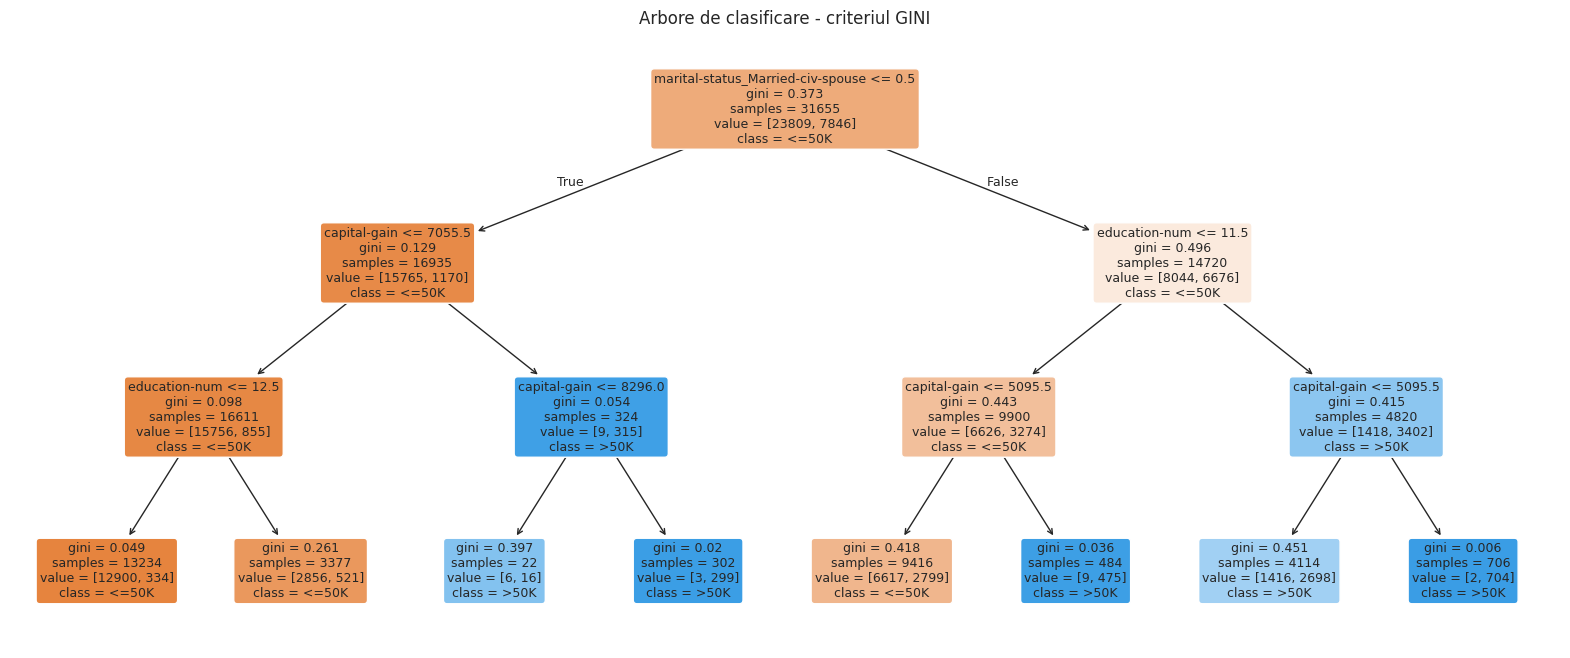

In [ ]:
# Arborele pentru criteriul GINI
plt.figure(figsize=(20, 8), dpi=100)
tree.plot_tree(clf_gini, feature_names=X_train.columns, class_names=['<=50K', '>50K'],
               filled=True, rounded=True, fontsize=9)
plt.title('Arbore de clasificare - criteriul GINI')
plt.savefig("dtree_gini.jpg", dpi=250)
plt.show()

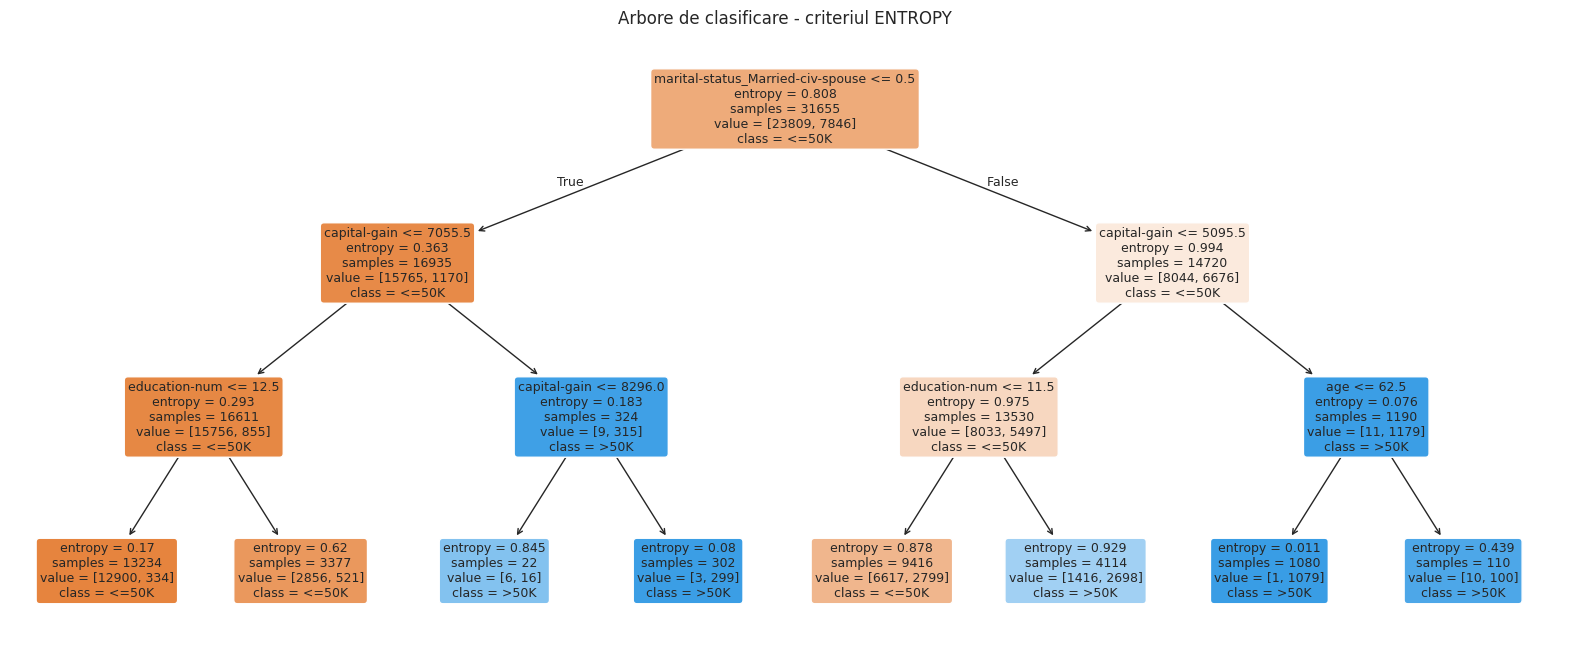

In [ ]:
# Arborele pentru criteriul ENTROPY
plt.figure(figsize=(20, 8), dpi=100)
tree.plot_tree(clf_entropy, feature_names=X_train.columns, class_names=['<=50K', '>50K'],
               filled=True, rounded=True, fontsize=9)
plt.title('Arbore de clasificare - criteriul ENTROPY')
plt.savefig("dtree_entropy.jpg", dpi=250)
plt.show()

**Interpretare:** prima împărțire (rădăcina) se face după variabila care separă cel mai bine cele două clase. Aici, faptul că persoana este căsătorită (`marital-status_Married-civ-spouse`) este cel mai important criteriu. Pe ramurile următoare apar nivelul de educație (`education-num`) și câștigurile de capital (`capital-gain`). Fiecare frunză are o clasă majoritară, iar culoarea ei arată cât de „pură” este frunza.

Arborele poate fi citit și sub formă de reguli de decizie:

In [ ]:
# Arborele GINI sub formă de reguli text
print(tree.export_text(clf_gini, feature_names=list(X_train.columns)))

|--- marital-status_Married-civ-spouse <= 0.50
|   |--- capital-gain <= 7055.50
|   |   |--- education-num <= 12.50
|   |   |   |--- class: 0
|   |   |--- education-num >  12.50
|   |   |   |--- class: 0
|   |--- capital-gain >  7055.50
|   |   |--- capital-gain <= 8296.00
|   |   |   |--- class: 1
|   |   |--- capital-gain >  8296.00
|   |   |   |--- class: 1
|--- marital-status_Married-civ-spouse >  0.50
|   |--- education-num <= 11.50
|   |   |--- capital-gain <= 5095.50
|   |   |   |--- class: 0
|   |   |--- capital-gain >  5095.50
|   |   |   |--- class: 1
|   |--- education-num >  11.50
|   |   |--- capital-gain <= 5095.50
|   |   |   |--- class: 1
|   |   |--- capital-gain >  5095.50
|   |   |   |--- class: 1



**Importanța variabilelor în arbore**

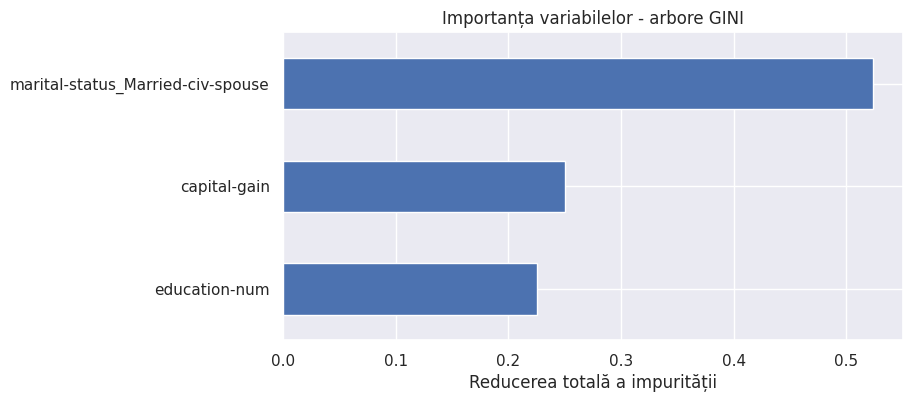

In [ ]:
importanta = pd.Series(clf_gini.feature_importances_, index=X_train.columns)
importanta = importanta[importanta > 0].sort_values()

plt.figure(figsize=(8, 4))
importanta.plot(kind='barh')
plt.title('Importanța variabilelor - arbore GINI')
plt.xlabel('Reducerea totală a impurității')
plt.show()

**Matricea de confuzie și raportul de clasificare**

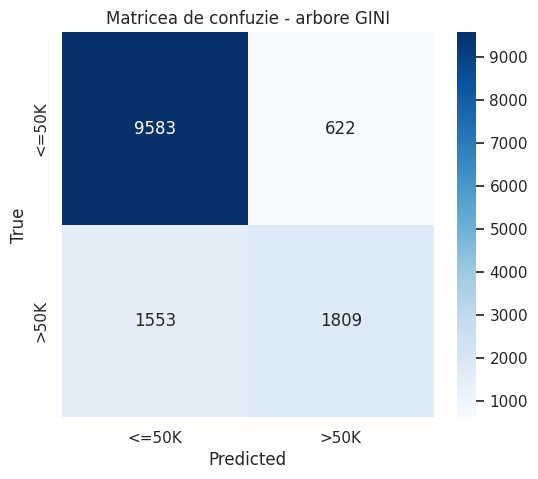

In [ ]:
# Calculați matricea de confuzie
confusion_mat = confusion_matrix(y_test, y_pred_gini)

# Afișați matricea de confuzie folosind seaborn și matplotlib
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Matricea de confuzie - arbore GINI')
plt.savefig("confusion_matrix_gini.jpg", dpi=250)
plt.show()

In [ ]:
print(classification_report(y_test, y_pred_gini))

              precision    recall  f1-score   support

           0       0.86      0.94      0.90     10205
           1       0.74      0.54      0.62      3362

    accuracy                           0.84     13567
   macro avg       0.80      0.74      0.76     13567
weighted avg       0.83      0.84      0.83     13567



**Curba ROC pentru cei doi arbori**

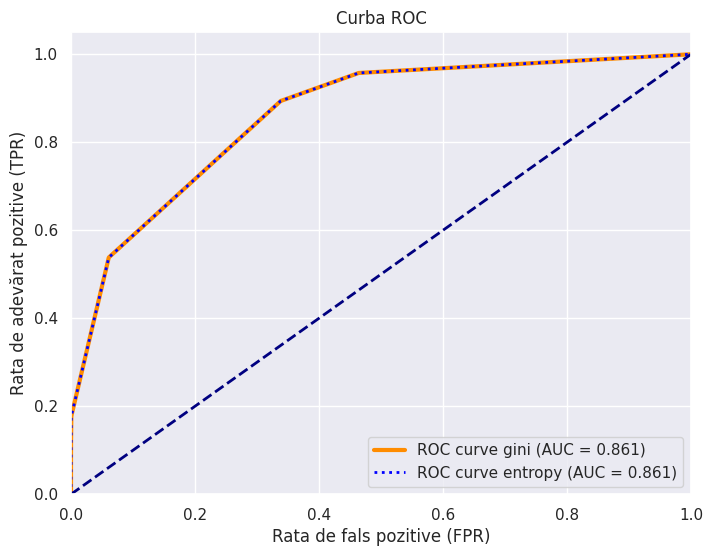

In [ ]:
# Calculați curba ROC pe baza probabilităților clasei pozitive (1 = venit >50K)
fpr, tpr, thresholds = roc_curve(y_test, y_prob_gini)
fpr1, tpr1, thresholds1 = roc_curve(y_test, y_prob_entropy)

# Calculați AUC (aria de sub curba ROC)
roc_auc = roc_auc_score(y_test, y_prob_gini)
roc_auc1 = roc_auc_score(y_test, y_prob_entropy)

# Trasați curba ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=3, label=f'ROC curve gini (AUC = {roc_auc:.3f})')
plt.plot(fpr1, tpr1, color='blue', lw=2, linestyle=':', label=f'ROC curve entropy (AUC = {roc_auc1:.3f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Rata de fals pozitive (FPR)')
plt.ylabel('Rata de adevărat pozitive (TPR)')
plt.title('Curba ROC')
plt.legend(loc='lower right')
plt.show()

**Alegerea adâncimii arborelui (overfitting)**

Un arbore cu `max_depth=3` este ușor de interpretat, dar poate fi prea simplu. Să vedem ce se întâmplă cu performanța pe datele de antrenare și pe cele de test când creștem adâncimea.

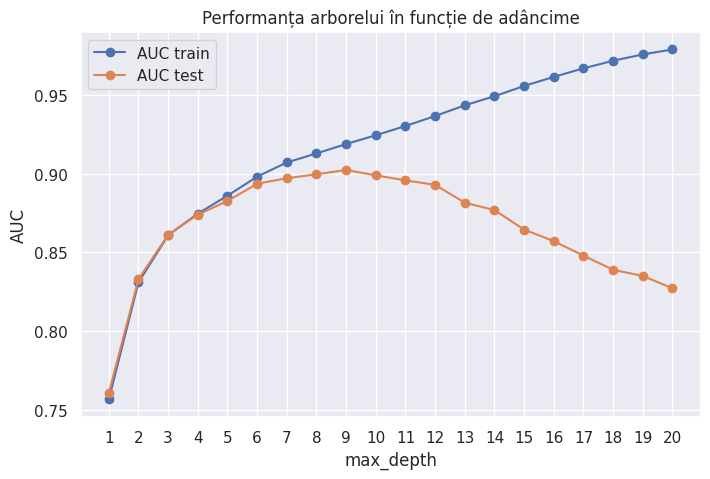

Adâncimea cu cel mai mare AUC pe test: 9  AUC = 0.9024


In [ ]:
adancimi = range(1, 21)
auc_train, auc_test = [], []

for d in adancimi:
    model = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=random_seed).fit(X_train, y_train)
    auc_train.append(roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]))
    auc_test.append(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))

plt.figure(figsize=(8, 5))
plt.plot(adancimi, auc_train, marker='o', label='AUC train')
plt.plot(adancimi, auc_test, marker='o', label='AUC test')
plt.xlabel('max_depth')
plt.ylabel('AUC')
plt.title('Performanța arborelui în funcție de adâncime')
plt.xticks(adancimi)
plt.legend()
plt.show()

best_depth = adancimi[int(np.argmax(auc_test))]
print('Adâncimea cu cel mai mare AUC pe test:', best_depth, ' AUC =', round(max(auc_test), 4))

**Interpretare:** pe datele de antrenare AUC-ul crește continuu cu adâncimea (arborele memorează datele), în timp ce pe datele de test crește până la o anumită adâncime și apoi scade – acesta este fenomenul de **overfitting**. Vom păstra în comparația finală și un arbore cu adâncimea optimă.

*Notă:* în practică adâncimea se alege prin validare încrucișată pe setul de antrenare (de ex. `GridSearchCV`), nu direct pe setul de test; aici folosim setul de test doar în scop ilustrativ.

In [ ]:
clf_best = DecisionTreeClassifier(criterion='gini', max_depth=best_depth, random_state=random_seed).fit(X_train, y_train)
y_pred_best = clf_best.predict(X_test)
y_prob_best = clf_best.predict_proba(X_test)[:, 1]

print(f"Arbore GINI, max_depth={best_depth}:  Accuracy = {accuracy_score(y_test, y_pred_best):.4f},  AUC = {roc_auc_score(y_test, y_prob_best):.4f}")

Arbore GINI, max_depth=9:  Accuracy = 0.8560,  AUC = 0.9024


## Selecția adâncimii arborelui prin GridSearchCV

**GridSearchCV** încearcă toate combinațiile de valori ale hiperparametrilor dintr-o grilă (`param_grid`) și, pentru fiecare combinație, estimează performanța prin **validare încrucișată (k-fold cross-validation)**:
1. setul de antrenare este împărțit în *k* părți (folds) – aici k = 5;
2. modelul este antrenat de 5 ori, de fiecare dată pe 4 părți, și evaluat pe partea rămasă;
3. scorul unei combinații este media celor 5 scoruri de validare;
4. se alege combinația cu cel mai bun scor mediu, iar modelul final este re-antrenat pe tot setul de antrenare (`refit=True`).

Parametri importanți:
- `param_grid` – dicționarul cu hiperparametrii și valorile încercate;
- `scoring` – metrica după care se alege modelul (aici `'roc_auc'`; alte variante: `'accuracy'`, `'f1'`, `'neg_log_loss'` etc.);
- `cv` – schema de validare încrucișată; `StratifiedKFold` păstrează proporția claselor în fiecare fold;
- `n_jobs=-1` – folosește toate procesoarele disponibile.

Vom căuta simultan adâncimea maximă (`max_depth` de la 2 la 15) și criteriul de selecție (`gini` sau `entropy`).

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    'max_depth': list(range(2, 16)),
    'criterion': ['gini', 'entropy']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_seed)

grid_tree = GridSearchCV(estimator=DecisionTreeClassifier(random_state=random_seed),
                         param_grid=param_grid,
                         scoring='roc_auc',
                         cv=cv,
                         n_jobs=-1,
                         return_train_score=True)

grid_tree.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=50, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=50), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,
                                       14, 15]},
             return_train_score=True, scoring='roc_auc')

**Rezultatele pentru toate combinațiile testate**

In [ ]:
rez_cv = pd.DataFrame(grid_tree.cv_results_)[['param_criterion', 'param_max_depth',
                                               'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']]
rez_cv.columns = ['criterion', 'max_depth', 'AUC_train', 'AUC_validare', 'std_validare', 'rang']
rez_cv.sort_values('rang').head(10).round(4)

,criterion,max_depth,AUC_train,AUC_validare,std_validare,rang
20,entropy,8,0.9133,0.8993,0.0037,1
6,gini,8,0.9131,0.8988,0.0037,2
19,entropy,7,0.9069,0.8986,0.0034,3
21,entropy,9,0.9190,0.8981,0.0043,4
5,gini,7,0.9065,0.8978,0.0027,5
7,gini,9,0.9197,0.8975,0.0042,6
22,entropy,10,0.9248,0.8962,0.0040,7
8,gini,10,0.9259,0.8933,0.0067,8
18,entropy,6,0.8990,0.8930,0.0039,9
23,entropy,11,0.9303,0.8927,0.0036,10


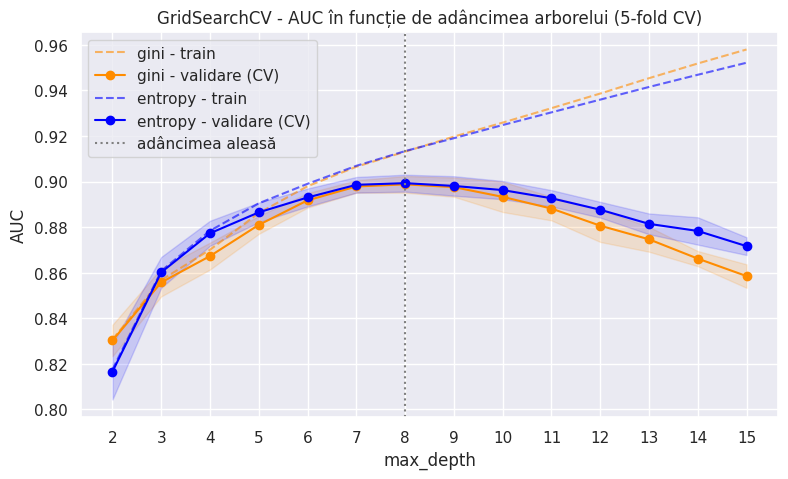

In [ ]:
# Graficul AUC mediu în validarea încrucișată în funcție de adâncime, pentru fiecare criteriu
plt.figure(figsize=(9, 5))
for crit, culoare in [('gini', 'darkorange'), ('entropy', 'blue')]:
    r = rez_cv[rez_cv['criterion'] == crit]
    plt.plot(r['max_depth'], r['AUC_train'], linestyle='--', color=culoare, alpha=0.6, label=f'{crit} - train')
    plt.plot(r['max_depth'], r['AUC_validare'], marker='o', color=culoare, label=f'{crit} - validare (CV)')
    plt.fill_between(r['max_depth'].astype(float),
                     r['AUC_validare'] - r['std_validare'],
                     r['AUC_validare'] + r['std_validare'], color=culoare, alpha=0.15)

plt.axvline(grid_tree.best_params_['max_depth'], color='grey', linestyle=':', label='adâncimea aleasă')
plt.xlabel('max_depth')
plt.ylabel('AUC')
plt.title('GridSearchCV - AUC în funcție de adâncimea arborelui (5-fold CV)')
plt.xticks(range(2, 16))
plt.legend()
plt.show()

**Interpretare:** curba de validare are aceeași formă ca graficul anterior: AUC-ul crește odată cu adâncimea, atinge un maxim și apoi începe să scadă, în timp ce AUC-ul pe datele de antrenare continuă să crească (overfitting). Banda colorată arată variabilitatea scorului între cele 5 folduri: este îngustă, deci estimarea este stabilă. Diferența dintre criteriile `gini` și `entropy` este din nou foarte mică.

Adâncimea a fost aleasă **fără să folosim setul de test**, deci evaluarea de mai jos este o estimare corectă a performanței modelului pe date noi.

In [ ]:
# Modelul final (re-antrenat automat pe tot setul de antrenare cu cei mai buni hiperparametri)
clf_best = grid_tree.best_estimator_
best_depth = grid_tree.best_params_['max_depth']
best_crit = grid_tree.best_params_['criterion']

y_pred_best = clf_best.predict(X_test)
y_prob_best = clf_best.predict_proba(X_test)[:, 1]

print(f"Arbore {best_crit.upper()}, max_depth={best_depth} (ales prin GridSearchCV)")
print("Accuracy: ", round(accuracy_score(y_test, y_pred_best), 4))
print("Precision:", round(precision_score(y_test, y_pred_best), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_best), 4))
print("AUC test: ", round(roc_auc_score(y_test, y_prob_best), 4))
print("Număr de frunze:", clf_best.get_n_leaves())

Arbore ENTROPY, max_depth=8 (ales prin GridSearchCV)
Accuracy:  0.8535
Precision: 0.7588
Recall:    0.5996
AUC test:  0.9009
Număr de frunze: 120


**Observație:** AUC-ul pe setul de test este foarte apropiat de AUC-ul mediu din validarea încrucișată, ceea ce confirmă că validarea încrucișată a estimat corect performanța pe date noi. Prețul unei performanțe mai bune este complexitatea: arborele are 120 de frunze, față de doar 8 frunze pentru arborele cu adâncimea 3, deci nu mai poate fi interpretat vizual.

# Regresia logistică

**LogisticRegression** din pachetul Scikit-learn implementează regresia logistică și poate folosi diferiți optimizatori numerici pentru a estima parametrii („newton-cg”, „lbfgs”, „liblinear”, „sag”, „saga”, „newton-cholesky”).
Puteți găsi informații detaliate despre avantajele și dezavantajele acestor optimizatori în documentația scikit-learn (https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression).
  - pentru seturi de date mici, ‘liblinear’ este o alegere bună, în timp ce ‘sag’ și ‘saga’ sunt mai rapizi pentru seturi mari;
  - pentru probleme cu mai multe clase, doar ‘newton-cg’, ‘sag’, ‘saga’ și ‘lbfgs’ folosesc funcția de pierdere multinomială;
  - ‘liblinear’ este limitat la schema one-versus-rest;
  - ‘newton-cholesky’ este o alegere bună când numărul de observații este mult mai mare decât numărul de variabile, mai ales cu variabile categoriale codificate one-hot.

Regresia logistică din Scikit-learn suportă regularizarea. Tipurile de penalizare suportate de fiecare optimizator:
 - ‘lbfgs’ - [‘l2’, None]
 - ‘liblinear’ - [‘l1’, ‘l2’]
 - ‘newton-cg’ - [‘l2’, None]
 - ‘newton-cholesky’ - [‘l2’, None]
 - ‘sag’ - [‘l2’, None]
 - ‘saga’ - [‘elasticnet’, ‘l1’, ‘l2’, None]

Parametrul **C** indică inversul puterii de regularizare și trebuie să fie un număr real pozitiv. Valorile mai mici specifică o regularizare mai puternică. Implicit se folosește penalizarea L2.

**Important:** spre deosebire de arbori, regresia logistică este sensibilă la scala variabilelor (de ex. `capital-gain` ia valori de până la 99.999, iar `age` între 17 și 90). De aceea **standardizăm** variabilele înainte de estimare. Scalerul se estimează **doar pe datele de antrenare** și apoi se aplică pe datele de test, pentru a nu „scurge” informație din setul de test în model.

In [ ]:
# Standardizarea variabilelor: (x - medie) / abatere standard
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # estimăm media și abaterea standard pe train
X_test_sc = scaler.transform(X_test)         # aplicăm aceleași valori pe test

pd.DataFrame(X_train_sc, columns=X_train.columns).describe().round(2).iloc[:, :5]

,age,education-num,capital-gain,capital-loss,hours-per-week
count,31655.00,31655.00,31655.00,31655.00,31655.00
mean,-0.00,-0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00
min,-1.63,-3.56,-0.15,-0.22,-3.31
25%,-0.80,-0.43,-0.15,-0.22,-0.08
50%,-0.12,-0.04,-0.15,-0.22,-0.08
75%,0.64,1.13,-0.15,-0.22,0.34
max,3.89,2.31,13.32,9.47,4.82


In [ ]:
LR = LogisticRegression(C=0.1, solver='liblinear', max_iter=1000).fit(X_train_sc, y_train)
LR

LogisticRegression(C=0.1, max_iter=1000, solver='liblinear')

**Predicția**

In [ ]:
# Valorile previzionate pentru y
y_pred_lr = LR.predict(X_test_sc)
y_pred_lr

array([0, 0, 1, ..., 0, 0, 0], shape=(13567,))

In [ ]:
# Valorile probabilităților previzionate pentru clase: prima coloană este probabilitatea clasei 0, P(Y=0|X),
# iar a doua coloană este probabilitatea clasei 1, P(Y=1|X):
y_pred_prob = LR.predict_proba(X_test_sc)
y_pred_prob

array([[0.6016278 , 0.3983722 ],
       [0.88803014, 0.11196986],
       [0.4253982 , 0.5746018 ],
       ...,
       [0.99802668, 0.00197332],
       [0.99026958, 0.00973042],
       [0.99015169, 0.00984831]], shape=(13567, 2))

**Evaluarea modelului**

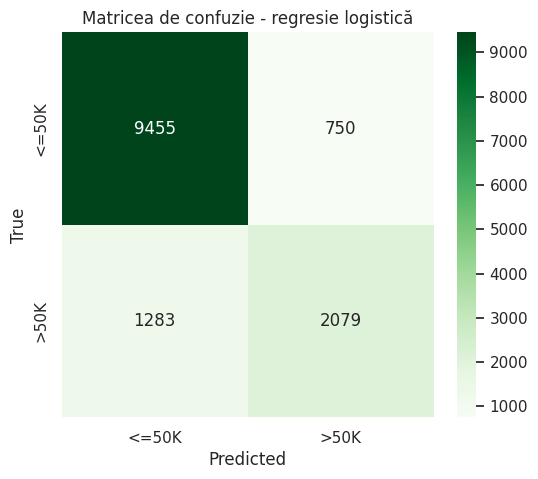

In [ ]:
# Matricea de confuzie
confusion_mat = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='Greens',
            xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Matricea de confuzie - regresie logistică')
plt.savefig("confusion_matrix_lr.jpg", dpi=250)
plt.show()

In [ ]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.88      0.93      0.90     10205
           1       0.73      0.62      0.67      3362

    accuracy                           0.85     13567
   macro avg       0.81      0.77      0.79     13567
weighted avg       0.84      0.85      0.85     13567



**Interpretare**

Precizie = TP / (TP + FP) – din persoanele pe care modelul le-a clasificat cu venit >50K, câte chiar au venit >50K.

Recall = TP / (TP + FN) – din persoanele care au într-adevăr venit >50K, câte au fost identificate de model.

Scorul F1: media armonică a preciziei și a recall-ului; atinge cea mai bună valoare la 1 (precizie și recall perfecte) și cea mai slabă la 0. Este o modalitate bună de a arăta că un clasificator are valori bune pentru ambele măsuri.

Observați că pentru clasa 1 (>50K), care este clasa minoritară, recall-ul este mai mic decât precizia: modelul „ratează” o parte din persoanele cu venit mare. Acest lucru se datorează dezechilibrului dintre clase și pragului implicit de 0,5.

In [ ]:
# Calculul log loss
log_loss(y_test, y_pred_prob)

0.325714067440741

**Interpretare:**
Log loss (entropia încrucișată) măsoară performanța unui clasificator al cărui rezultat este o probabilitate între 0 și 1. Penalizează puternic predicțiile greșite făcute cu încredere mare. **Cu cât valoarea este mai apropiată de 0, cu atât clasificatorul este mai bun.** Ca reper, un model care ar prezice pentru toată lumea probabilitatea medie a clasei 1 (~0,25) ar avea un log loss de aproximativ 0,56.

In [ ]:
# Log loss pentru un model de referință care prezice mereu proporția clasei 1 din train
p_ref = np.full(len(y_test), y_train.mean())
print('Log loss model de referință:', round(log_loss(y_test, p_ref), 4))
print('Log loss regresie logistică:', round(log_loss(y_test, y_pred_prob), 4))
print('Log loss arbore GINI (d=3): ', round(log_loss(y_test, y_prob_gini), 4))

Log loss model de referință: 0.5599
Log loss regresie logistică: 0.3257
Log loss arbore GINI (d=3):  0.3631


**Interpretarea coeficienților**

Un avantaj important al regresiei logistice este că estimează un coeficient pentru fiecare variabilă. Deoarece variabilele sunt standardizate, coeficienții pot fi comparați între ei:
- un coeficient **pozitiv** crește probabilitatea ca persoana să aibă venit >50K;
- un coeficient **negativ** scade această probabilitate;
- **exp(coeficient)** = *odds ratio*: de câte ori se modifică șansele (odds) de a avea venit >50K la creșterea variabilei cu o abatere standard.

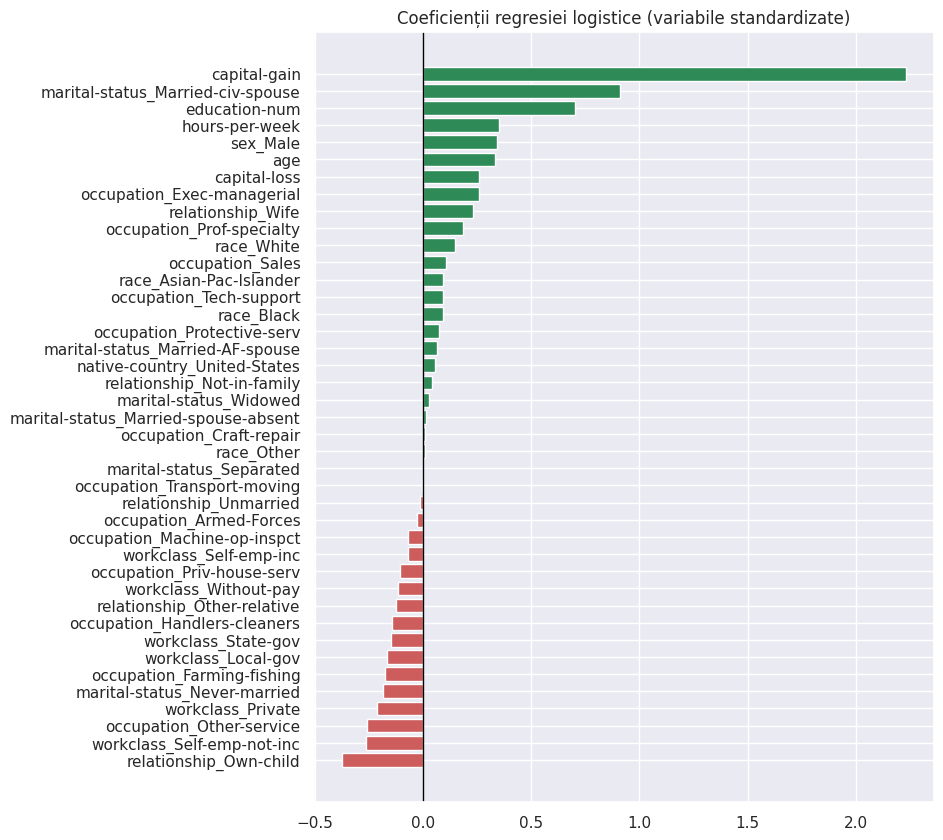

,coeficient,odds_ratio
capital-gain,2.231,9.312
marital-status_Married-civ-spouse,0.909,2.483
education-num,0.701,2.016
hours-per-week,0.350,1.419
sex_Male,0.341,1.406
age,0.332,1.394
capital-loss,0.259,1.296
occupation_Exec-managerial,0.257,1.293


In [ ]:
coef = pd.DataFrame({'coeficient': LR.coef_[0], 'odds_ratio': np.exp(LR.coef_[0])}, index=X_train.columns)
coef = coef.sort_values('coeficient')

plt.figure(figsize=(8, 10))
plt.barh(coef.index, coef['coeficient'], color=np.where(coef['coeficient'] > 0, 'seagreen', 'indianred'))
plt.axvline(0, color='black', lw=1)
plt.title('Coeficienții regresiei logistice (variabile standardizate)')
plt.show()

coef.sort_values('coeficient', ascending=False).head(8).round(3)

**Interpretare:** cele mai mari efecte pozitive le au câștigurile de capital, starea civilă de persoană căsătorită și nivelul de educație. De exemplu, creșterea `education-num` cu o abatere standard (aproximativ 2,5 niveluri de educație) multiplică șansele de a avea venit >50K cu valoarea din coloana `odds_ratio`. Observați că variabilele importante sunt în mare parte aceleași cu cele alese de arbore.

**Efectul regularizării (parametrul C)**

In [ ]:
for C in [0.0001, 0.001, 0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=C, solver='liblinear', max_iter=1000).fit(X_train_sc, y_train)
    p = m.predict_proba(X_test_sc)[:, 1]
    print(f"C = {C:<7}  AUC = {roc_auc_score(y_test, p):.4f}   log loss = {log_loss(y_test, p):.4f}")

C = 0.0001   AUC = 0.8924   log loss = 0.4751
C = 0.001    AUC = 0.9005   log loss = 0.3562
C = 0.01     AUC = 0.9045   log loss = 0.3280
C = 0.1      AUC = 0.9047   log loss = 0.3257
C = 1        AUC = 0.9046   log loss = 0.3259
C = 10       AUC = 0.9046   log loss = 0.3260


**Interpretare:** o regularizare foarte puternică (C foarte mic) micșorează prea mult coeficienții și înrăutățește modelul; de la o anumită valoare a lui C în sus performanța se stabilizează, pentru că avem multe observații în raport cu numărul de variabile.

# Compararea modelelor: arbori de clasificare vs. regresie logistică

In [ ]:
modele = {
    'Arbore GINI (d=3)':           (y_pred_gini,    y_prob_gini),
    'Arbore ENTROPY (d=3)':        (y_pred_entropy, y_prob_entropy),
    f'Arbore GINI (d={best_depth})': (y_pred_best,    y_prob_best),
    'Regresie logistică':          (y_pred_lr,      y_pred_prob[:, 1]),
}

rezultate = pd.DataFrame({
    nume: {'Accuracy':  accuracy_score(y_test, yp),
           'Precision': precision_score(y_test, yp),
           'Recall':    recall_score(y_test, yp),
           'F1':        f1_score(y_test, yp),
           'AUC':       roc_auc_score(y_test, pr),
           'Log loss':  log_loss(y_test, pr)}
    for nume, (yp, pr) in modele.items()
}).T

rezultate.round(4)

,Accuracy,Precision,Recall,F1,AUC,Log loss
Arbore GINI (d=3),0.8397,0.7441,0.5381,0.6245,0.8612,0.3631
Arbore ENTROPY (d=3),0.8397,0.7441,0.5381,0.6245,0.8612,0.3635
Arbore GINI (d=9),0.8560,0.7739,0.5916,0.6706,0.9024,0.4237
Regresie logistică,0.8502,0.7349,0.6184,0.6716,0.9047,0.3257


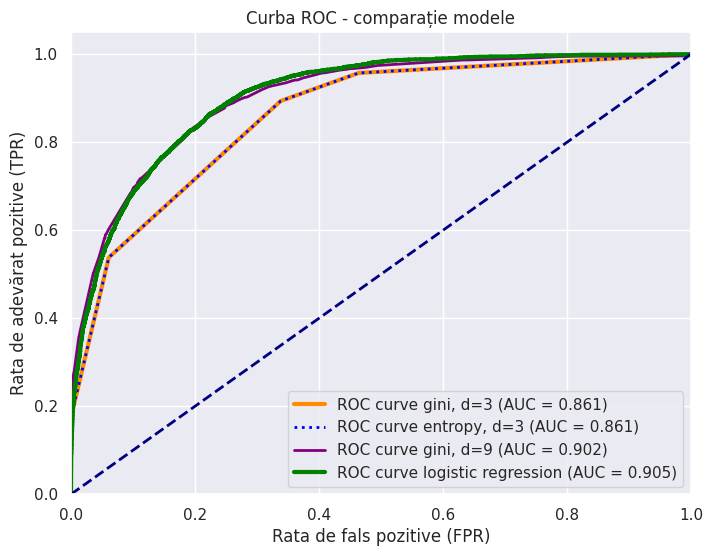

In [ ]:
# Curbele ROC pentru toate modelele
y_scores  = y_prob_gini
y_scores1 = y_prob_entropy
y_scores2 = y_pred_prob[:, 1]
y_scores3 = y_prob_best

fpr,  tpr,  _ = roc_curve(y_test, y_scores)
fpr1, tpr1, _ = roc_curve(y_test, y_scores1)
fpr2, tpr2, _ = roc_curve(y_test, y_scores2)
fpr3, tpr3, _ = roc_curve(y_test, y_scores3)

roc_auc  = roc_auc_score(y_test, y_scores)
roc_auc1 = roc_auc_score(y_test, y_scores1)
roc_auc2 = roc_auc_score(y_test, y_scores2)
roc_auc3 = roc_auc_score(y_test, y_scores3)

plt.figure(figsize=(8, 6))
plt.plot(fpr,  tpr,  color='darkorange', lw=3, label=f'ROC curve gini, d=3 (AUC = {roc_auc:.3f})')
plt.plot(fpr1, tpr1, color='blue', lw=2, linestyle=':', label=f'ROC curve entropy, d=3 (AUC = {roc_auc1:.3f})')
plt.plot(fpr3, tpr3, color='purple', lw=2, label=f'ROC curve gini, d={best_depth} (AUC = {roc_auc3:.3f})')
plt.plot(fpr2, tpr2, color='green', lw=3, label=f'ROC curve logistic regression (AUC = {roc_auc2:.3f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Rata de fals pozitive (FPR)')
plt.ylabel('Rata de adevărat pozitive (TPR)')
plt.title('Curba ROC - comparație modele')
plt.legend(loc='lower right')
plt.show()

# Concluzii

- Toate modelele depășesc clar modelul „naiv” (acuratețe ~75%, AUC = 0,5).
- Criteriile GINI și ENTROPY produc aici arbori foarte asemănători, cu predicții identice.
- Arborii cu adâncimea 3 au un **AUC mai mic** (~0,86) decât regresia logistică (~0,90): având doar 8 frunze, ei produc doar câteva valori distincte ale probabilității, deci ordonează mai grosier persoanele (curba ROC este formată din câteva segmente).
- Arborele cu adâncimea 9 ajunge la un AUC apropiat de cel al regresiei logistice și chiar la o acuratețe și o precizie puțin mai mari, dar are un **log loss mai mare** (probabilitățile din frunzele mici sunt extreme și mai puțin de încredere) și nu mai poate fi interpretat vizual.
- **Regresia logistică** obține cel mai mare AUC, cel mai mare recall pentru clasa `>50K` și cel mai mic log loss, deci oferă probabilități mai bine calibrate. În plus, coeficienții săi au o interpretare directă (odds ratio).
- **Arborele de decizie** are avantajul unor reguli simple, ușor de explicat unui public non-tehnic, nu necesită standardizarea datelor și surprinde automat interacțiunile dintre variabile.
- Alegerea între modele depinde de obiectiv: dacă ne interesează calitatea probabilităților estimate și interpretarea efectelor, alegem regresia logistică; dacă ne interesează reguli de decizie simple și transparente, un arbore de adâncime mică este o alegere bună.

# Exerciții

1. Re-estimați arborele GINI folosind `class_weight='balanced'`. Cum se modifică precizia și recall-ul pentru clasa `>50K`? Faceți același lucru pentru regresia logistică.
2. Pentru regresia logistică, modificați pragul de decizie de la 0,5 la 0,3 (folosind `y_pred_prob[:, 1] > 0.3`). Calculați din nou matricea de confuzie și raportul de clasificare. Ce observați?
3. Folosiți `GridSearchCV` cu validare încrucișată (cv=5) pe setul de antrenare pentru a alege `max_depth` și `min_samples_leaf` ai arborelui, cu `scoring='roc_auc'`.
4. Estimați o regresie logistică cu penalizare L1 (`solver='liblinear'`, `penalty='l1'`, C=0.01). Câți coeficienți devin exact 0? Ce variabile rămân în model?